## Analyse des tendances temporelles et de la saisonnalité des ventes

### Objectif
Cette analyse vise à étudier l’évolution des ventes dans le temps afin d’identifier :
- les tendances globales (hausse / baisse),
- les cycles saisonniers (mois ou trimestres forts/faibles),
- les périodes clés pour l’activité commerciale.

### Intérêt métier
L’analyse temporelle permet :
- d’anticiper les pics et creux de ventes,
- d’optimiser la planification des stocks,
- d’adapter les campagnes marketing selon les périodes,
- d’améliorer la prévision du chiffre d’affaires.

In [2]:
# Suppression des warnings non bloquants pour améliorer la lisibilité du notebook
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
from pathlib import Path
import os, sys

import pandas as pd
import numpy as np

# 1) Trouver la racine du projet (là où il y a requirements.txt / src / visualizations)
PROJECT_ROOT = None
for p in Path().resolve().parents:
    if (p / "requirements.txt").exists() and (p / "src").exists() and (p / "visualizations").exists():
        PROJECT_ROOT = p
        break

if PROJECT_ROOT is None:
    raise RuntimeError("Impossible de trouver la racine du projet. Vérifie que requirements.txt, src, visualizations existent.")

# 2) Ajouter le projet au PYTHONPATH (pour pouvoir importer src.analysis.db)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 3) Dossier de sortie des images (partie 4)
OUTPUT_DIR = PROJECT_ROOT / "visualizations" / "part4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT, OUTPUT_DIR

(WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis'),
 WindowsPath('C:/Users/canpe/Documents/classicmodels-analysis/visualizations/part4'))

On calcule automatiquement la racine du projet et le dossier de sortie afin de garantir la portabilité et la reproductibilité, quel que soit le dossier depuis lequel le notebook est exécuté.

In [4]:
from src.analysis.db import get_connection

def fetch_df(query: str, params=None) -> pd.DataFrame:
    """
    Exécute une requête SQL (paramétrée si besoin) et renvoie un DataFrame.
    On ouvre/ferme proprement la connexion à chaque appel.
    """
    conn = get_connection()
    try:
        return pd.read_sql(query, conn, params=params)
    finally:
        conn.close()

On centralise l’exécution SQL dans une fonction unique pour éviter la duplication, réduire les erreurs et garantir la fermeture systématique des connexions.

In [5]:
conn = get_connection()
conn

In [6]:
conn.close()

Ce test valide que l’environnement, les credentials et la base MySQL sont correctement accessibles avant d’exécuter l’analyse.

In [7]:
ts_sql = """
SELECT
    DATE_FORMAT(p.paymentDate, '%Y-%m') AS period,
    SUM(p.amount) AS total_sales
FROM payments p
GROUP BY period
ORDER BY period
"""
ts = fetch_df(ts_sql)
ts["period"] = pd.to_datetime(ts["period"])
ts.head()

,period,total_sales
0,2003-01-01,26267.62
1,2003-02-01,144384.36
2,2003-03-01,199704.48
3,2003-04-01,136313.92
4,2003-05-01,159881.97


Les ventes sont agrégées par période mensuelle afin de lisser les variations journalières et de faciliter l’analyse des tendances et de la saisonnalité.

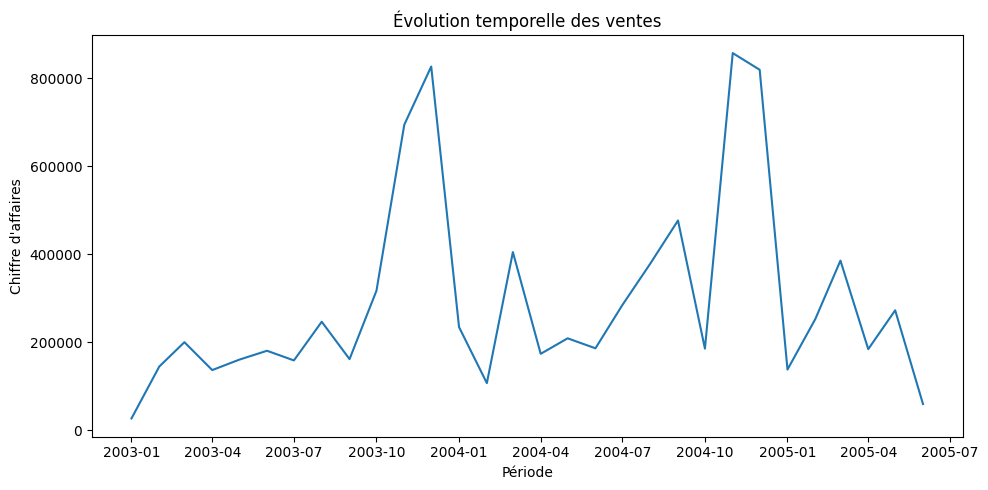

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.lineplot(data=ts, x="period", y="total_sales")
plt.title("Évolution temporelle des ventes")
plt.xlabel("Période")
plt.ylabel("Chiffre d'affaires")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "03_time_series_trend.png", dpi=300)
plt.show()

L’analyse de la tendance temporelle permet d’identifier les phases de croissance ou de ralentissement de l’activité, essentielles pour la stratégie commerciale et financière.

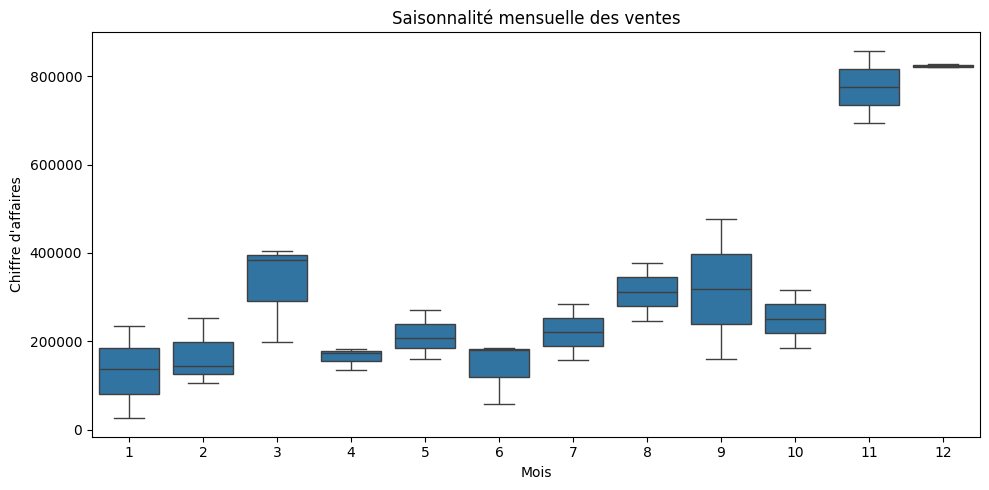

In [9]:
ts["month"] = ts["period"].dt.month
ts["year"] = ts["period"].dt.year

plt.figure(figsize=(10,5))
sns.boxplot(data=ts, x="month", y="total_sales")
plt.title("Saisonnalité mensuelle des ventes")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "03_seasonality_month.png", dpi=300)
plt.show()

La visualisation de la saisonnalité met en évidence les périodes récurrentes de forte ou faible activité, facilitant l’optimisation des stocks et des actions marketing.

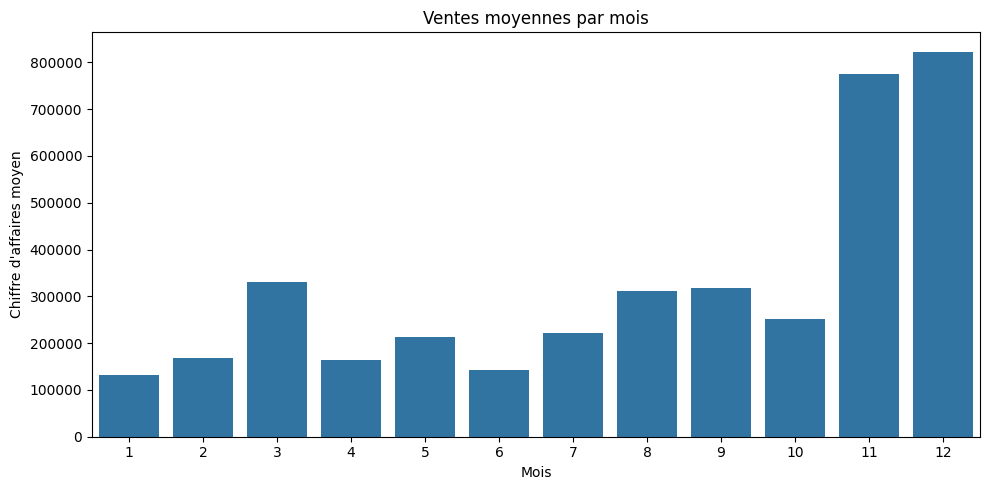

In [10]:
monthly_avg = ts.groupby("month")["total_sales"].mean().reset_index()

plt.figure(figsize=(10,5))
sns.barplot(data=monthly_avg, x="month", y="total_sales")
plt.title("Ventes moyennes par mois")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires moyen")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "03_monthly_avg_sales.png", dpi=300)
plt.show()

Les moyennes mensuelles permettent d’identifier rapidement les mois stratégiques sur le long terme, indépendamment des fluctuations ponctuelles.

### Conclusion

L’analyse temporelle met en évidence :
- une tendance globale des ventes identifiable dans le temps,
- des effets saisonniers marqués sur certains mois,
- des périodes stratégiques nécessitant une anticipation opérationnelle.

Ces résultats peuvent être exploités pour :
- ajuster les niveaux de stock,
- planifier les campagnes promotionnelles,
- améliorer la prévision du chiffre d’affaires.